In [9]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv('uber.csv')
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [11]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [12]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [13]:
#Preprocessing
df = df.drop(["Unnamed: 0", "key"], axis = 1)
df = df.dropna()
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199999 entries, 0 to 199999
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype              
---  ------             --------------   -----              
 0   fare_amount        199999 non-null  float64            
 1   pickup_datetime    199999 non-null  datetime64[ns, UTC]
 2   pickup_longitude   199999 non-null  float64            
 3   pickup_latitude    199999 non-null  float64            
 4   dropoff_longitude  199999 non-null  float64            
 5   dropoff_latitude   199999 non-null  float64            
 6   passenger_count    199999 non-null  int64              
dtypes: datetime64[ns, UTC](1), float64(5), int64(1)
memory usage: 12.2 MB


In [14]:
#Extract time features
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek

df = df.drop("pickup_datetime", axis=1)
df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


In [17]:
#calculating distance
lat1 = np.radians(df["pickup_latitude"])
lon1 = np.radians(df["pickup_longitude"])
lat2 = np.radians(df["dropoff_latitude"])
lon2 = np.radians(df["dropoff_longitude"])

dlat = lat2 - lat1
dlon = lon2 - lon1

a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
df["distance"] = 6371 * 2 * np.arcsin(np.sqrt(a))

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,distance
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3,4.475450


In [18]:
df.describe()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,distance
count,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000,199999.000000
mean,11.359892,-72.527631,39.935881,-72.525292,39.923890,1.684543,13.491387,15.704739,6.281791,2011.742434,3.048435,20.855350
std,9.901760,11.437815,7.720558,13.117408,6.794829,1.385995,6.515505,8.687377,3.438933,1.856400,1.946946,382.964642
min,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000,0.000000,1.000000,1.000000,2009.000000,0.000000,0.000000
25%,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000,9.000000,8.000000,3.000000,2010.000000,1.000000,1.215222
50%,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000,14.000000,16.000000,6.000000,2012.000000,3.000000,2.120992
75%,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000,19.000000,23.000000,9.000000,2013.000000,5.000000,3.875169
max,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000,23.000000,31.000000,12.000000,2015.000000,6.000000,16409.239135


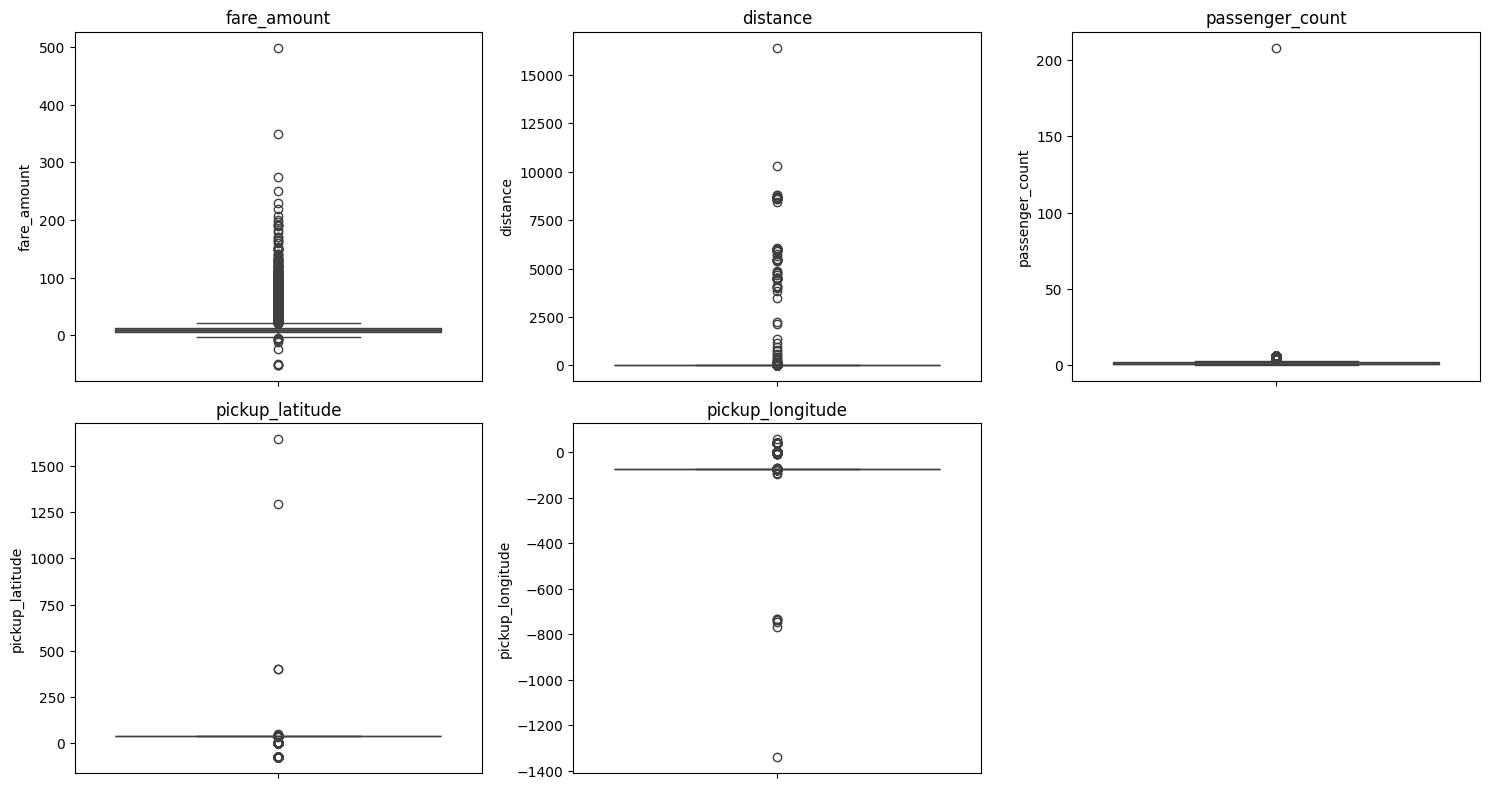

In [20]:
#boxplot(outliers)
plt.figure(figsize=(15, 8))
cols = ["fare_amount", "distance", "passenger_count", "pickup_latitude", "pickup_longitude"]
for i, col in enumerate(cols):
    plt.subplot(2, 3, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [23]:
#removing outliers
df = df[(df["fare_amount"] > 0) & (df["fare_amount"] <= 100)]
df = df[(df["distance"] > 0) & (df["distance"] <= 60)]
df = df[(df["passenger_count"] > 0) & (df["passenger_count"] <= 6)]
df = df[(df["pickup_latitude"].between(-90, 90)) & (df["dropoff_latitude"].between(-90, 90))]
df = df[(df["pickup_longitude"].between(-180, 180)) & (df["dropoff_longitude"].between(-180, 180))]

df.shape

(193098, 12)

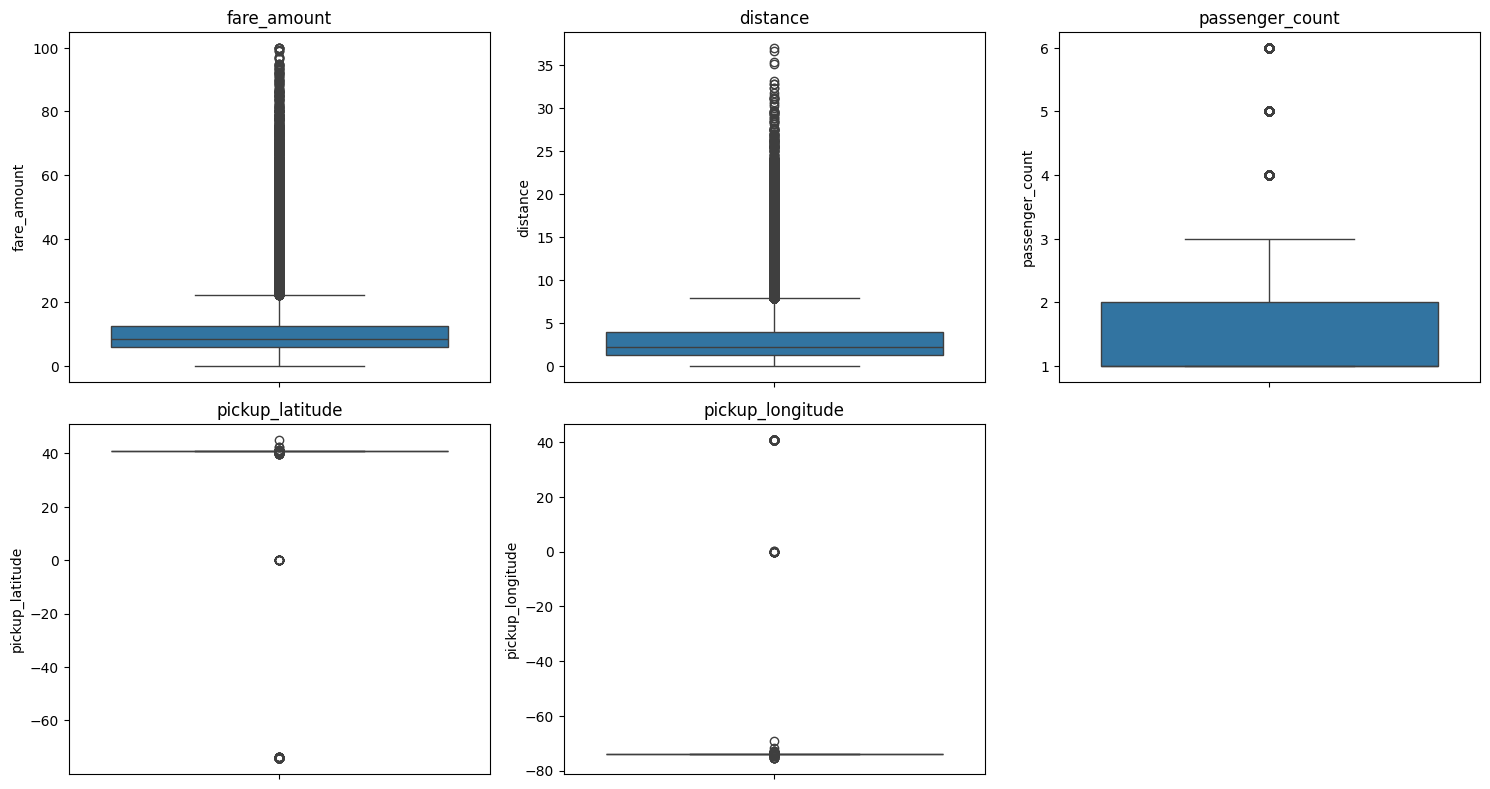

In [24]:
plt.figure(figsize=(15, 8))
cols = ["fare_amount", "distance", "passenger_count", "pickup_latitude", "pickup_longitude"]
for i, col in enumerate(cols):
    plt.subplot(2, 3, i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [25]:
df.corr()["fare_amount"].sort_values(ascending=False)

fare_amount          1.000000
distance             0.887280
year                 0.122901
month                0.024738
passenger_count      0.013729
pickup_longitude     0.012169
dropoff_longitude    0.010718
dayofweek            0.004935
day                  0.000853
dropoff_latitude    -0.008948
pickup_latitude     -0.009004
hour                -0.020701
Name: fare_amount, dtype: float64

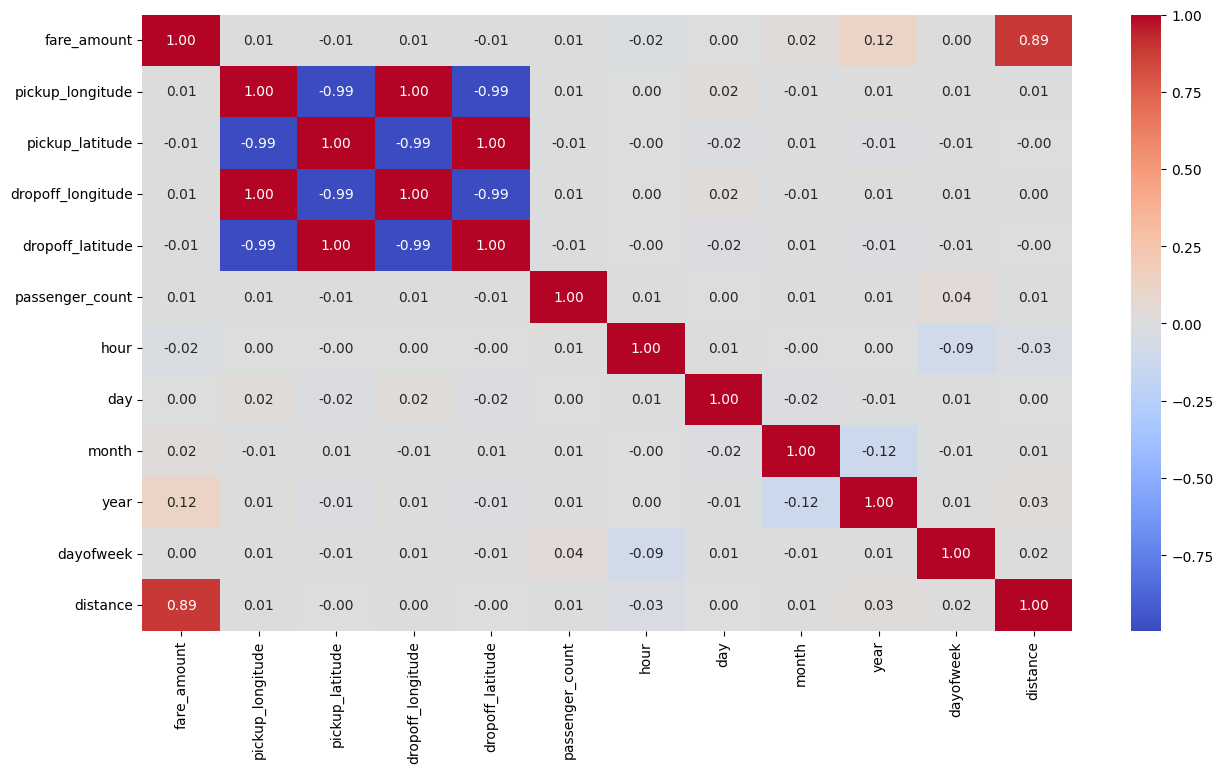

In [26]:
plt.figure(figsize=(15,8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [27]:
from sklearn.model_selection import train_test_split

X = df.drop("fare_amount", axis = 1)
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)

(154478, 11) (38620, 11)


In [31]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

y_predlr = lr.predict(X_test)
y_predlr[:5]

array([ 7.16771481,  4.0028097 , 42.07410402,  4.7114623 ,  8.42331503])

In [32]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

rf.fit(X_train, y_train)

y_predrf = rf.predict(X_test)
y_predrf[:5]

array([ 6.578 , 11.685 , 39.0475,  4.955 ,  7.11  ])

In [33]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Linear Regression")
print("R2: ", r2_score(y_test, y_predlr))
print("RMSE: ", np.sqrt(mean_squared_error(y_test, y_predlr)))
print("MAE: ", mean_absolute_error(y_test, y_predlr))

print("\nRandom Forest")
print("R2: ", r2_score(y_test, y_predrf))
print("RMSE: ", np.sqrt(mean_squared_error(y_test, y_predrf)))
print("MAE: ", mean_absolute_error(y_test, y_predrf))

Linear Regression
R2:  0.7842732964019922
RMSE:  4.410214210797628
MAE:  2.2514071355864105

Random Forest
R2:  0.8554329586531103
RMSE:  3.6102924003513834
MAE:  1.7896266934230967
